1: Import required Libraries

In [ ]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt


In [ ]:
df=pd.read_excel('Telco_customer_churn.xlsx')

In [ ]:
df.head()

,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,...,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,...,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,...,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,...,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,...,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 33 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         7043 non-null   object 
 1   Count              7043 non-null   int64  
 2   Country            7043 non-null   object 
 3   State              7043 non-null   object 
 4   City               7043 non-null   object 
 5   Zip Code           7043 non-null   int64  
 6   Lat Long           7043 non-null   object 
 7   Latitude           7043 non-null   float64
 8   Longitude          7043 non-null   float64
 9   Gender             7043 non-null   object 
 10  Senior Citizen     7043 non-null   object 
 11  Partner            7043 non-null   object 
 12  Dependents         7043 non-null   object 
 13  Tenure Months      7043 non-null   int64  
 14  Phone Service      7043 non-null   object 
 15  Multiple Lines     7043 non-null   object 
 16  Internet Service   7043 

In [ ]:
df.shape

(7043, 33)

In [ ]:
df.columns

Index(['CustomerID', 'Count', 'Country', 'State', 'City', 'Zip Code',
       'Lat Long', 'Latitude', 'Longitude', 'Gender', 'Senior Citizen',
       'Partner', 'Dependents', 'Tenure Months', 'Phone Service',
       'Multiple Lines', 'Internet Service', 'Online Security',
       'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV',
       'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method',
       'Monthly Charges', 'Total Charges', 'Churn Label', 'Churn Value',
       'Churn Score', 'CLTV', 'Churn Reason'],
      dtype='object')

In [ ]:
df.isnull().sum()

CustomerID              0
Count                   0
Country                 0
State                   0
City                    0
Zip Code                0
Lat Long                0
Latitude                0
Longitude               0
Gender                  0
Senior Citizen          0
Partner                 0
Dependents              0
Tenure Months           0
Phone Service           0
Multiple Lines          0
Internet Service        0
Online Security         0
Online Backup           0
Device Protection       0
Tech Support            0
Streaming TV            0
Streaming Movies        0
Contract                0
Paperless Billing       0
Payment Method          0
Monthly Charges         0
Total Charges           0
Churn Label             0
Churn Value             0
Churn Score             0
CLTV                    0
Churn Reason         5174
dtype: int64

In [ ]:
# conclusion--imbalanced dataset

In [ ]:
## to check duplicate records
df[df.duplicated()]

,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason


In [ ]:
df_clean = df.copy()

In [ ]:
df_clean['Total Charges'].unique()

array([108.15, 151.65, 820.5, ..., 7362.9, 346.45, 6844.5],
      shape=(6531,), dtype=object)

In [ ]:
df_clean['Total Charges'] = pd.to_numeric(
    df_clean['Total Charges'].astype(str).str.strip(),
    errors='coerce'
)

In [ ]:
df_clean['Total Charges'].isnull().sum()

np.int64(11)

In [ ]:
df_clean.loc[
    df_clean['Total Charges'].isnull(),
    ['Tenure Months', 'Monthly Charges', 'Total Charges']
]

,Tenure Months,Monthly Charges,Total Charges
2234,0,52.55,NaN
2438,0,20.25,NaN
2568,0,80.85,NaN
2667,0,25.75,NaN
2856,0,56.05,NaN
4331,0,19.85,NaN
4687,0,25.35,NaN
5104,0,20.00,NaN
5719,0,19.70,NaN
6772,0,73.35,NaN


In [ ]:
df_clean['Total Charges'] = df_clean['Total Charges'].fillna(0)

In [ ]:
for col in df_clean.select_dtypes(include='object').columns:
    df_clean[col] = df_clean[col].str.strip()

In [ ]:
df_clean.duplicated().sum()

np.int64(0)

In [ ]:
print("Dataset Shape:", df_clean.shape)

print("\nMissing Values:")
print(df_clean.isnull().sum()[df_clean.isnull().sum() > 0])

print("\nData Types:")
print(df_clean.dtypes)

print("\nDuplicates:", df_clean.duplicated().sum())

Dataset Shape: (7043, 33)

Missing Values:
Churn Reason    5174
dtype: int64

Data Types:
CustomerID            object
Count                  int64
Country               object
State                 object
City                  object
Zip Code               int64
Lat Long              object
Latitude             float64
Longitude            float64
Gender                object
Senior Citizen        object
Partner               object
Dependents            object
Tenure Months          int64
Phone Service         object
Multiple Lines        object
Internet Service      object
Online Security       object
Online Backup         object
Device Protection     object
Tech Support          object
Streaming TV          object
Streaming Movies      object
Contract              object
Paperless Billing     object
Payment Method        object
Monthly Charges      float64
Total Charges        float64
Churn Label           object
Churn Value            int64
Churn Score            int64
CLTV       

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

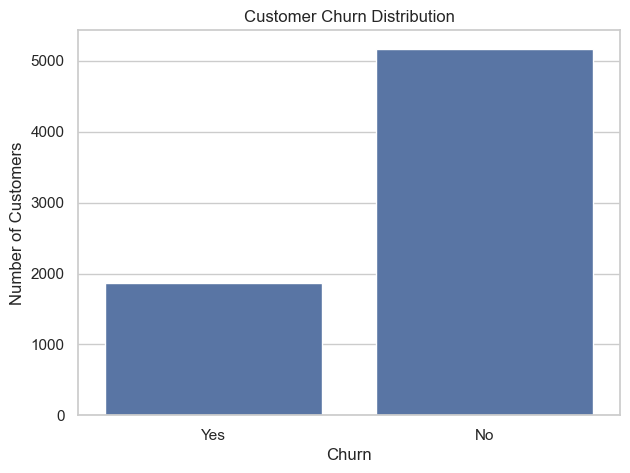

In [ ]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df_clean, x='Churn Label')

plt.title('Customer Churn Distribution')
plt.xlabel('Churn')
plt.ylabel('Number of Customers')

plt.show()

In [ ]:
df_clean['Churn Label'].value_counts(normalize=True) * 100

Churn Label
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

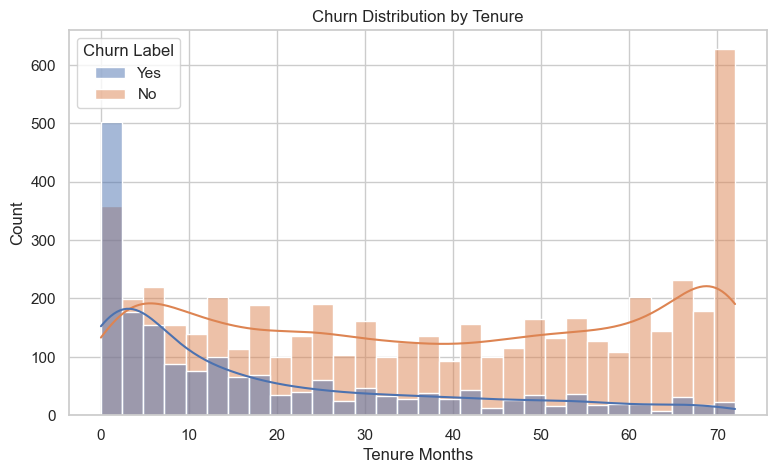

In [ ]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df_clean,
    x='Tenure Months',
    hue='Churn Label',
    bins=30,
    kde=True
)

plt.title('Churn Distribution by Tenure')
plt.show()

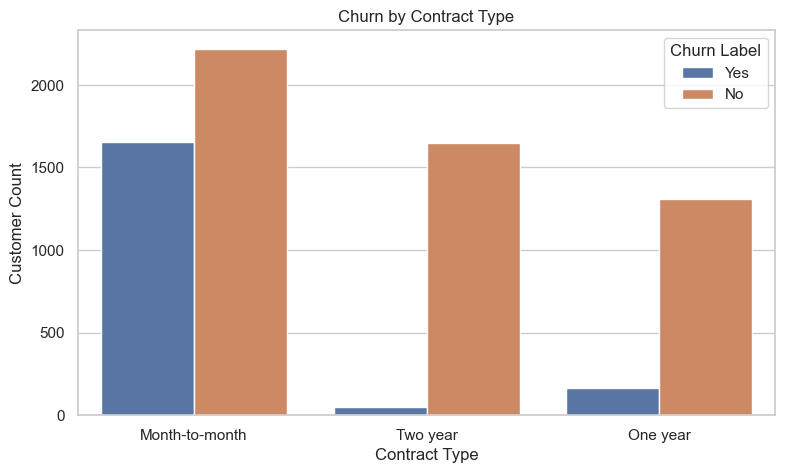

In [ ]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df_clean,
    x='Contract',
    hue='Churn Label'
)

plt.title('Churn by Contract Type')
plt.xlabel('Contract Type')
plt.ylabel('Customer Count')

plt.show()

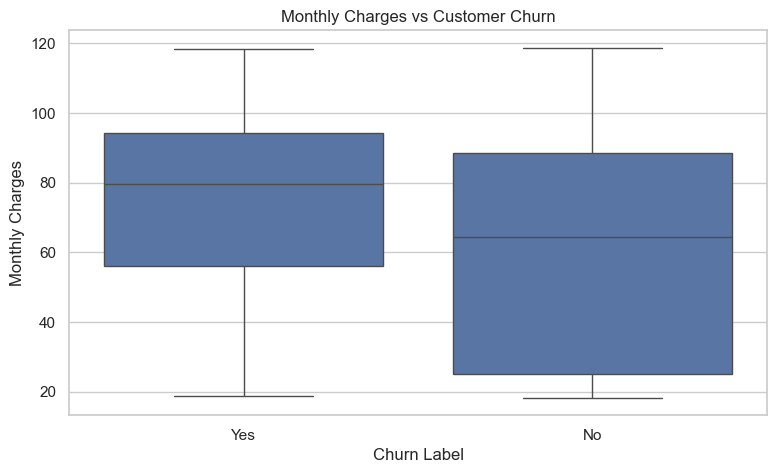

In [ ]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df_clean,
    x='Churn Label',
    y='Monthly Charges'
)

plt.title('Monthly Charges vs Customer Churn')
plt.show()

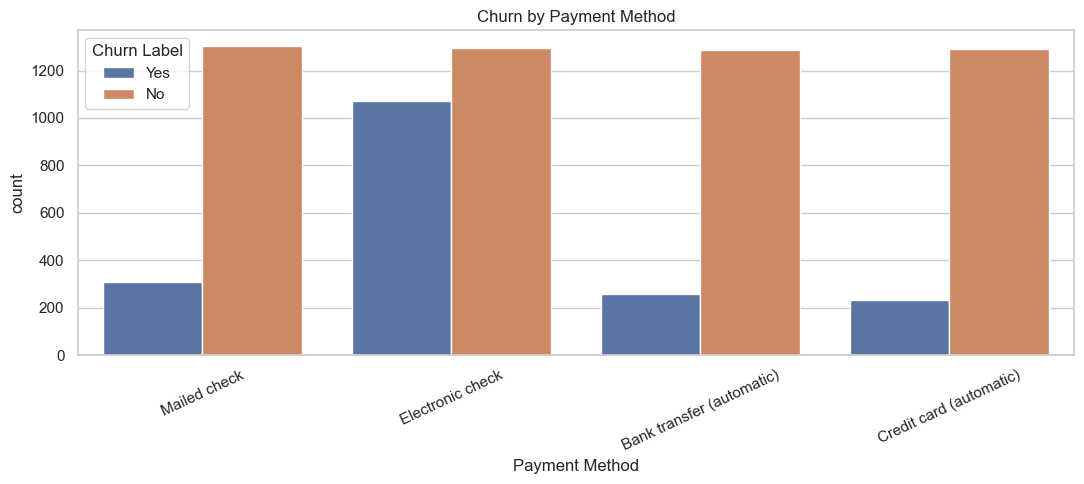

In [ ]:
plt.figure(figsize=(11, 5))

sns.countplot(
    data=df_clean,
    x='Payment Method',
    hue='Churn Label'

)

plt.xticks(rotation=25)
plt.title('Churn by Payment Method')
plt.tight_layout()
plt.show()

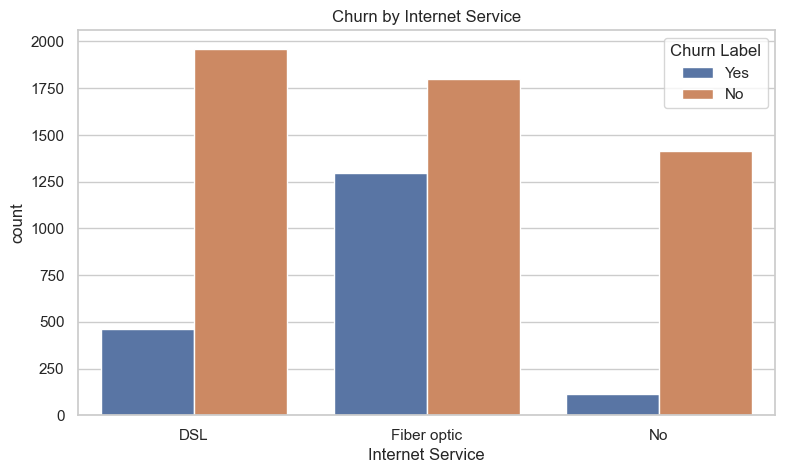

In [ ]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df_clean,
    x='Internet Service',
    hue='Churn Label'
)

plt.title('Churn by Internet Service')
plt.show()

In [ ]:
contract_churn = pd.crosstab(
    df_clean['Contract'],
    df_clean['Churn Label'],
    normalize='index'
) * 100

print(contract_churn)

Churn Label            No        Yes
Contract                            
Month-to-month  57.290323  42.709677
One year        88.730482  11.269518
Two year        97.168142   2.831858


In [ ]:
df_clean['Tenure Group'] = pd.cut(
    df_clean['Tenure Months'],
    bins=[-1, 12, 24, 48, 60, float('inf')],
    labels=[
        '0-12 Months',
        '13-24 Months',
        '25-48 Months',
        '49-60 Months',
        '61+ Months'
    ]
)

In [ ]:
df_clean['Tenure Group'].value_counts().sort_index()

Tenure Group
0-12 Months     2186
13-24 Months    1024
25-48 Months    1594
49-60 Months     832
61+ Months      1407
Name: count, dtype: int64

In [ ]:
tenure = df_clean['Tenure Months'].replace(0, np.nan)

df_clean['Average Monthly Spend'] = (
    df_clean['Total Charges'] / tenure
)

df_clean['Average Monthly Spend'] = (
    df_clean['Average Monthly Spend']
    .fillna(df_clean['Monthly Charges'])
)

In [ ]:
service_columns = [
    'Multiple Lines',
    'Online Security',
    'Online Backup',
    'Device Protection',
    'Tech Support',
    'Streaming TV',
    'Streaming Movies'
]

df_clean['Add-on Services Count'] = (
    df_clean[service_columns] == 'Yes'
).sum(axis=1)

In [ ]:
df_clean['Contract Risk'] = (
    df_clean['Contract'] == 'Month-to-month'
).astype(int)

In [ ]:
new_features = [
    'Tenure Group',
    'Average Monthly Spend',
    'Add-on Services Count',
    'Contract Risk'
]

df_clean[new_features].head(10)

,Tenure Group,Average Monthly Spend,Add-on Services Count,Contract Risk
0,0-12 Months,54.075000,2,1
1,0-12 Months,75.825000,0,1
2,0-12 Months,102.562500,4,1
3,25-48 Months,108.787500,5,1
4,49-60 Months,102.781633,5,1
5,0-12 Months,52.835000,2,1
6,0-12 Months,39.650000,2,1
7,0-12 Months,20.150000,0,1
8,25-48 Months,101.045745,4,1
9,0-12 Months,30.200000,1,1


In [ ]:
df_clean[new_features].describe(include='all')

,Tenure Group,Average Monthly Spend,Add-on Services Count,Contract Risk
count,7043,7043.000000,7043.000000,7043.000000
unique,5,NaN,NaN,NaN
top,0-12 Months,NaN,NaN,NaN
freq,2186,NaN,NaN,NaN
mean,NaN,64.762906,2.459747,0.550192
std,NaN,30.189796,2.045539,0.497510
min,NaN,13.775000,0.000000,0.000000
25%,NaN,35.935156,1.000000,0.000000
50%,NaN,70.337500,2.000000,1.000000
75%,NaN,90.174158,4.000000,1.000000


In [ ]:
tenure_analysis = (
    df_clean.groupby('Tenure Group', observed=False)['Churn Value']
    .mean() * 100
)

print(tenure_analysis.round(2))

Tenure Group
0-12 Months     47.44
13-24 Months    28.71
25-48 Months    20.39
49-60 Months    14.42
61+ Months       6.61
Name: Churn Value, dtype: float64


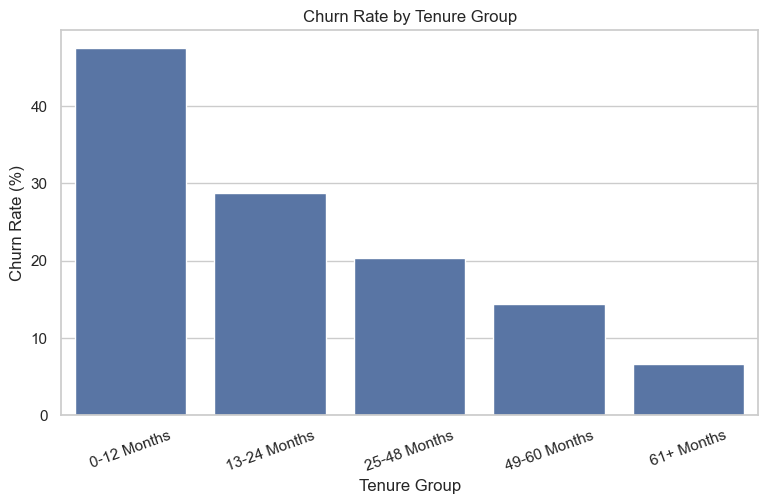

In [ ]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=tenure_analysis.index,
    y=tenure_analysis.values
)

plt.title('Churn Rate by Tenure Group')
plt.xlabel('Tenure Group')
plt.ylabel('Churn Rate (%)')

plt.xticks(rotation=20)
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

In [ ]:
target = 'Churn Value'

y = df_clean[target].astype(int)

In [ ]:
categorical_features = [
    'Gender',
    'Senior Citizen',
    'Partner',
    'Dependents',
    'Phone Service',
    'Multiple Lines',
    'Internet Service',
    'Online Security',
    'Online Backup',
    'Device Protection',
    'Tech Support',
    'Streaming TV',
    'Streaming Movies',
    'Contract',
    'Paperless Billing',
    'Payment Method'
]

numerical_features = [
    'Tenure Months',
    'Monthly Charges',
    'Total Charges'
]

In [ ]:
X = df_clean[
    categorical_features + numerical_features
].copy()

In [ ]:
print(X.shape)
print(y.shape)

print(X.head())

(7043, 19)
(7043,)
   Gender Senior Citizen Partner Dependents Phone Service Multiple Lines  \
0    Male             No      No         No           Yes             No   
1  Female             No      No        Yes           Yes             No   
2  Female             No      No        Yes           Yes            Yes   
3  Female             No     Yes        Yes           Yes            Yes   
4    Male             No      No        Yes           Yes            Yes   

  Internet Service Online Security Online Backup Device Protection  \
0              DSL             Yes           Yes                No   
1      Fiber optic              No            No                No   
2      Fiber optic              No            No               Yes   
3      Fiber optic              No            No               Yes   
4      Fiber optic              No           Yes               Yes   

  Tech Support Streaming TV Streaming Movies        Contract  \
0           No           No            

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [ ]:
categorical_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(
            handle_unknown='ignore',
            drop='if_binary'
        ))
    ]
)

In [ ]:
numerical_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ]
)

In [ ]:
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', categorical_transformer, categorical_features),
        ('num', numerical_transformer, numerical_features)
    ]
)

In [ ]:
X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

In [ ]:
print("Original training shape:", X_train.shape)

print("Processed training shape:", X_train_processed.shape)

print("Original testing shape:", X_test.shape)

print("Processed testing shape:", X_test_processed.shape)

Original training shape: (5634, 19)
Processed training shape: (5634, 40)
Original testing shape: (1409, 19)
Processed testing shape: (1409, 40)


In [ ]:
feature_names = preprocessor.get_feature_names_out()

print(feature_names)
print("Total encoded features:", len(feature_names))

['cat__Gender_Male' 'cat__Senior Citizen_Yes' 'cat__Partner_Yes'
 'cat__Dependents_Yes' 'cat__Phone Service_Yes' 'cat__Multiple Lines_No'
 'cat__Multiple Lines_No phone service' 'cat__Multiple Lines_Yes'
 'cat__Internet Service_DSL' 'cat__Internet Service_Fiber optic'
 'cat__Internet Service_No' 'cat__Online Security_No'
 'cat__Online Security_No internet service' 'cat__Online Security_Yes'
 'cat__Online Backup_No' 'cat__Online Backup_No internet service'
 'cat__Online Backup_Yes' 'cat__Device Protection_No'
 'cat__Device Protection_No internet service' 'cat__Device Protection_Yes'
 'cat__Tech Support_No' 'cat__Tech Support_No internet service'
 'cat__Tech Support_Yes' 'cat__Streaming TV_No'
 'cat__Streaming TV_No internet service' 'cat__Streaming TV_Yes'
 'cat__Streaming Movies_No' 'cat__Streaming Movies_No internet service'
 'cat__Streaming Movies_Yes' 'cat__Contract_Month-to-month'
 'cat__Contract_One year' 'cat__Contract_Two year'
 'cat__Paperless Billing_Yes'
 'cat__Payment Method

In [ ]:
class_weight='balanced'

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix
)

import pandas as pd

In [ ]:
models = {
    'LR Normal': LogisticRegression(
        max_iter=2000,
        random_state=42
    ),

    'LR Balanced': LogisticRegression(
        max_iter=2000,
        class_weight='balanced',
        random_state=42
    ),

    'RF Normal': RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    ),

    'RF Balanced': RandomForestClassifier(
        n_estimators=300,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    )
}

In [ ]:
results = []
trained_models = {}

for name, model in models.items():

    # Train model
    model.fit(X_train_processed, y_train)

    # Predictions
    y_pred = model.predict(X_test_processed)

    # Churn probabilities
    y_prob = model.predict_proba(X_test_processed)[:, 1]

    # Evaluation
    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1 Score': f1_score(y_test, y_pred),
        'ROC AUC': roc_auc_score(y_test, y_prob),
        'PR AUC': average_precision_score(y_test, y_prob)
    })

    trained_models[name] = model

    print(f"\n{'='*40}")
    print(name)
    print('='*40)

    print(classification_report(
        y_test,
        y_pred,
        target_names=['No Churn', 'Churn'],
        zero_division=0
    ))


LR Normal
              precision    recall  f1-score   support

    No Churn       0.85      0.89      0.87      1035
       Churn       0.64      0.57      0.60       374

    accuracy                           0.80      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.80      0.80      1409


LR Balanced
              precision    recall  f1-score   support

    No Churn       0.90      0.73      0.81      1035
       Churn       0.51      0.78      0.62       374

    accuracy                           0.74      1409
   macro avg       0.71      0.75      0.71      1409
weighted avg       0.80      0.74      0.76      1409


RF Normal
              precision    recall  f1-score   support

    No Churn       0.84      0.88      0.86      1035
       Churn       0.62      0.52      0.56       374

    accuracy                           0.79      1409
   macro avg       0.73      0.70      0.71      1409
weighted avg       0.78      0.79      

In [ ]:
results_df = pd.DataFrame(results)

results_df.round(4)

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC,PR AUC
0,LR Normal,0.8020,0.6435,0.5695,0.6043,0.8490,0.6454
1,LR Balanced,0.7431,0.5105,0.7781,0.6165,0.8488,0.6452
2,RF Normal,0.7864,0.6151,0.5214,0.5644,0.8312,0.6247
3,RF Balanced,0.7899,0.6300,0.5053,0.5608,0.8348,0.6281


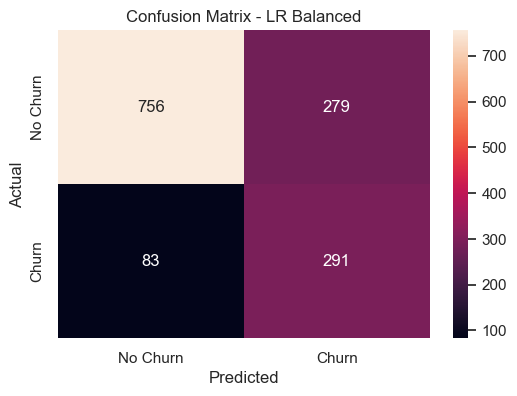

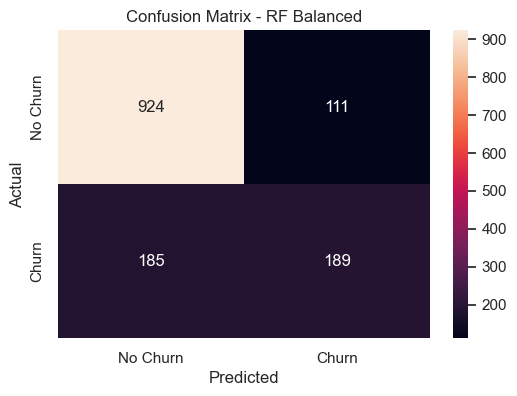

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

for name in ['LR Balanced', 'RF Balanced']:

    model = trained_models[name]

    y_pred = model.predict(X_test_processed)

    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(6, 4))

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        xticklabels=['No Churn', 'Churn'],
        yticklabels=['No Churn', 'Churn']
    )

    plt.title(f'Confusion Matrix - {name}')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')

    plt.show()

In [ ]:
from sklearn.model_selection import train_test_split

from sklearn.base import clone

X_subtrain, X_val, y_subtrain, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

In [ ]:
val_preprocessor = clone(preprocessor)

X_subtrain_processed = val_preprocessor.fit_transform(
    X_subtrain
)

X_val_processed = val_preprocessor.transform(
    X_val
)

In [ ]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(
    max_iter=2000,
    class_weight='balanced',
    random_state=42
)

lr_model.fit(
    X_subtrain_processed,
    y_subtrain
)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,'balanced'
,random_state,42
,solver,'lbfgs'
,max_iter,2000
,multi_class,'deprecated'


In [ ]:
y_val_prob = lr_model.predict_proba(
    X_val_processed
)[:, 1]

In [ ]:
import numpy as np

from sklearn.metrics import (
    precision_recall_curve,
    precision_score,
    recall_score,
    fbeta_score,
    confusion_matrix
)

# Step 1: Predict churn probabilities
y_val_prob = lr_model.predict_proba(X_val_processed)[:, 1]

# Step 2: Calculate precision and recall at different thresholds
precision, recall, thresholds = precision_recall_curve(
    y_val,
    y_val_prob
)

# Step 3: Calculate F2 scores
f2_scores = (
    5 * precision[:-1] * recall[:-1]
) / (
    4 * precision[:-1] + recall[:-1] + 1e-10
)

# Step 4: Find the best threshold
best_index = np.argmax(f2_scores)
best_threshold = thresholds[best_index]

# Step 5: Generate predictions using the best threshold
y_val_pred = (y_val_prob >= best_threshold).astype(int)

# Step 6: Evaluate
print("Best Threshold:", best_threshold)
print("Precision:", precision_score(y_val, y_val_pred))
print("Recall:", recall_score(y_val, y_val_pred))
print("F2 Score:", fbeta_score(y_val, y_val_pred, beta=2))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_val_pred))

Best Threshold: 0.42101341918405577
Precision: 0.4942528735632184
Recall: 0.862876254180602
F2 Score: 0.7508731082654249

Confusion Matrix:
[[564 264]
 [ 41 258]]


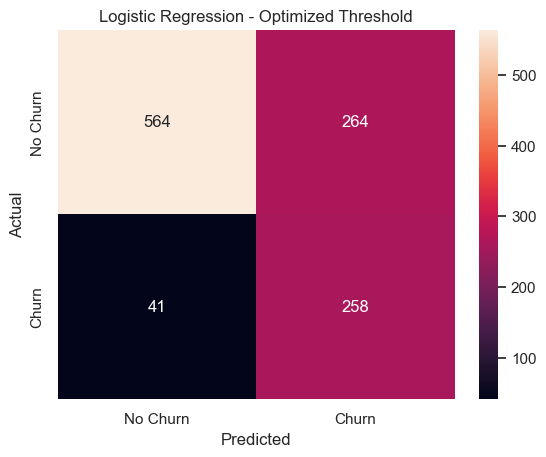

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_val, y_val_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    xticklabels=['No Churn', 'Churn'],
    yticklabels=['No Churn', 'Churn']
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Logistic Regression - Optimized Threshold")
plt.show()

In [ ]:
from sklearn.base import clone

final_preprocessor = clone(preprocessor)

X_train_final = final_preprocessor.fit_transform(X_train)

X_test_final = final_preprocessor.transform(X_test)

In [ ]:
from sklearn.linear_model import LogisticRegression

final_model = LogisticRegression(
    max_iter=2000,
    class_weight='balanced',
    random_state=42
)

final_model.fit(X_train_final, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,'balanced'
,random_state,42
,solver,'lbfgs'
,max_iter,2000
,multi_class,'deprecated'


In [ ]:
y_test_prob = final_model.predict_proba(
    X_test_final
)[:, 1]

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)

selected_threshold = best_threshold

thresholds_to_test = {
    'Default 0.50': 0.50,
    'Optimized 0.421': selected_threshold
}

for name, threshold in thresholds_to_test.items():

    y_test_pred = (
        y_test_prob >= threshold
    ).astype(int)

    print("\n", name)

    print("Accuracy:",
          accuracy_score(y_test, y_test_pred))

    print("Precision:",
          precision_score(y_test, y_test_pred))

    print("Recall:",
          recall_score(y_test, y_test_pred))

    print("F1 Score:",
          f1_score(y_test, y_test_pred))

    print("F2 Score:",
          fbeta_score(y_test, y_test_pred, beta=2))

    print("Confusion Matrix:")
    print(confusion_matrix(y_test, y_test_pred))

print("\nROC AUC:", roc_auc_score(y_test, y_test_prob))

print("Average Precision:",
      average_precision_score(y_test, y_test_prob))


 Default 0.50
Accuracy: 0.7430801987224982
Precision: 0.5105263157894737
Recall: 0.7780748663101604
F1 Score: 0.6165254237288136
F2 Score: 0.7042594385285575
Confusion Matrix:
[[756 279]
 [ 83 291]]

 Optimized 0.421
Accuracy: 0.7217885024840313
Precision: 0.4863636363636364
Recall: 0.8582887700534759
F1 Score: 0.620889748549323
F2 Score: 0.7444341372912802
Confusion Matrix:
[[696 339]
 [ 53 321]]

ROC AUC: 0.8488465214807925
Average Precision: 0.645180754875629


In [ ]:
import joblib
import os

os.makedirs("models", exist_ok=True)

joblib.dump(
    final_model,
    "models/churn_model.pkl"
)

joblib.dump(
    final_preprocessor,
    "models/churn_preprocessor.pkl"
)

['models/churn_preprocessor.pkl']

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.base import clone

from sklearn.model_selection import (
    RandomizedSearchCV,
    StratifiedKFold
)

rf_pipeline = Pipeline([
    ('preprocessor', clone(preprocessor)),

    ('classifier', RandomForestClassifier(
        random_state=42,
        n_jobs=1
    ))
])

In [ ]:
param_grid = {
    'classifier__n_estimators': [200, 300, 500],

    'classifier__max_depth': [
        None, 8, 12, 16, 20
    ],

    'classifier__min_samples_split': [
        2, 5, 10
    ],

    'classifier__min_samples_leaf': [
        1, 2, 4
    ],

    'classifier__max_features': [
        'sqrt', 'log2'
    ],

    'classifier__class_weight': [
        None,
        'balanced',
        'balanced_subsample'
    ]
}

In [ ]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [ ]:
rf_search = RandomizedSearchCV(
    estimator=rf_pipeline,

    param_distributions=param_grid,

    n_iter=20,

    scoring='average_precision',

    cv=cv,

    random_state=42,

    n_jobs=-1,

    verbose=1
)

rf_search.fit(X_subtrain, y_subtrain)

Fitting 5 folds for each of 20 candidates, totalling 100 fits


,estimator,Pipeline(step...m_state=42))])
,param_distributions,"{'classifier__class_weight': [None, 'balanced', ...], 'classifier__max_depth': [None, 8, ...], 'classifier__max_features': ['sqrt', 'log2'], 'classifier__min_samples_leaf': [1, 2, ...], ...}"
,n_iter,20
,scoring,'average_precision'
,n_jobs,-1
,refit,True
,cv,StratifiedKFo... shuffle=True)
,verbose,1
,pre_dispatch,'2*n_jobs'
,random_state,42
,error_score,nan


In [ ]:
print("Best Parameters:")
print(rf_search.best_params_)

print("\nBest Cross Validation Average Precision:")

print(rf_search.best_score_)

Best Parameters:
{'classifier__n_estimators': 200, 'classifier__min_samples_split': 5, 'classifier__min_samples_leaf': 2, 'classifier__max_features': 'sqrt', 'classifier__max_depth': 8, 'classifier__class_weight': None}

Best Cross Validation Average Precision:
0.6787099053098177


In [ ]:
from sklearn.metrics import (
    precision_recall_curve,
    precision_score,
    recall_score,
    fbeta_score,
    confusion_matrix
)

best_rf_model = rf_search.best_estimator_

rf_val_prob = best_rf_model.predict_proba(X_val)[:, 1]

precision, recall, thresholds = precision_recall_curve(
    y_val,
    rf_val_prob
)

f2_scores = (
    5 * precision[:-1] * recall[:-1]
) / (
    4 * precision[:-1] + recall[:-1] + 1e-10
)

rf_best_index = f2_scores.argmax()

rf_best_threshold = thresholds[rf_best_index]

rf_val_pred = (
    rf_val_prob >= rf_best_threshold
).astype(int)

print("Best RF Threshold:", rf_best_threshold)

print("Precision:", precision_score(y_val, rf_val_pred))

print("Recall:", recall_score(y_val, rf_val_pred))

print("F2 Score:", fbeta_score(
    y_val,
    rf_val_pred,
    beta=2
))

print("\nConfusion Matrix:")

print(confusion_matrix(y_val, rf_val_pred))

Best RF Threshold: 0.137758350226151
Precision: 0.4266263237518911
Recall: 0.9431438127090301
F2 Score: 0.7592891760904685

Confusion Matrix:
[[449 379]
 [ 17 282]]


In [ ]:
from sklearn.metrics import average_precision_score

lr_val_pred = (
    y_val_prob >= best_threshold
).astype(int)

comparison = pd.DataFrame([
    {
        'Model': 'Logistic Regression',
        'Threshold': best_threshold,
        'Precision': precision_score(y_val, lr_val_pred),
        'Recall': recall_score(y_val, lr_val_pred),
        'F2 Score': fbeta_score(y_val, lr_val_pred, beta=2),
        'Average Precision': average_precision_score(
            y_val, y_val_prob
        )
    },

    {
        'Model': 'Tuned Random Forest',
        'Threshold': rf_best_threshold,
        'Precision': precision_score(y_val, rf_val_pred),
        'Recall': recall_score(y_val, rf_val_pred),
        'F2 Score': fbeta_score(y_val, rf_val_pred, beta=2),
        'Average Precision': average_precision_score(
            y_val, rf_val_prob
        )
    }
])

print(comparison.round(4))

                 Model  Threshold  Precision  Recall  F2 Score  \
0  Logistic Regression     0.4210     0.4943  0.8629    0.7509   
1  Tuned Random Forest     0.1378     0.4266  0.9431    0.7593   

   Average Precision  
0             0.6911  
1             0.6796  


In [ ]:
from sklearn.base import clone

final_rf_model = clone(best_rf_model)

final_rf_model.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('cat', ...), ('num', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [ ]:
rf_test_prob = final_rf_model.predict_proba(X_test)[:, 1]

In [ ]:
rf_test_pred = (
    rf_test_prob >= rf_best_threshold
).astype(int)

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

print("Random Forest Final Test Results")

print("Threshold:", rf_best_threshold)

print("Accuracy:", accuracy_score(y_test, rf_test_pred))

print("Precision:", precision_score(y_test, rf_test_pred))

print("Recall:", recall_score(y_test, rf_test_pred))

print("F1 Score:", f1_score(y_test, rf_test_pred))

print("F2 Score:", fbeta_score(
    y_test, rf_test_pred, beta=2
))

print("ROC AUC:", roc_auc_score(y_test, rf_test_prob))

print("Average Precision:", average_precision_score(
    y_test, rf_test_prob
))

print("\nConfusion Matrix:")

print(confusion_matrix(y_test, rf_test_pred))

Random Forest Final Test Results
Threshold: 0.137758350226151
Accuracy: 0.6486870120652946
Precision: 0.4259485924112607
Recall: 0.93048128342246
F1 Score: 0.5843828715365239
F2 Score: 0.7522697795071336
ROC AUC: 0.8510863106771035
Average Precision: 0.6699944420286841

Confusion Matrix:
[[566 469]
 [ 26 348]]


In [ ]:
lr_test_prob = final_model.predict_proba(X_test_final)[:, 1]

lr_test_pred = (
    lr_test_prob >= best_threshold
).astype(int)

def evaluate_model(name, y_true, y_pred, y_prob):

    return {
        'Model': name,
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred),
        'Recall': recall_score(y_true, y_pred),
        'F1 Score': f1_score(y_true, y_pred),
        'F2 Score': fbeta_score(y_true, y_pred, beta=2),
        'ROC AUC': roc_auc_score(y_true, y_prob),
        'Average Precision': average_precision_score(
            y_true, y_prob
        )
    }

final_comparison = pd.DataFrame([
    evaluate_model(
        'Logistic Regression',
        y_test,
        lr_test_pred,
        lr_test_prob
    ),

    evaluate_model(
        'Random Forest',
        y_test,
        rf_test_pred,
        rf_test_prob
    )
])

print(final_comparison.round(4).to_string(index=False))

              Model  Accuracy  Precision  Recall  F1 Score  F2 Score  ROC AUC  Average Precision
Logistic Regression    0.7218     0.4864  0.8583    0.6209    0.7444   0.8488             0.6452
      Random Forest    0.6487     0.4259  0.9305    0.5844    0.7523   0.8511             0.6700


In [ ]:
import pandas as pd
import numpy as np

customer_risk = pd.DataFrame({
    'CustomerID': df_clean.loc[X_test.index, 'CustomerID'].values,
    'Actual Churn': y_test.values,
    'Churn Score': rf_test_prob
})

In [ ]:
conditions = [
    customer_risk['Churn Score'] < rf_best_threshold,

    customer_risk['Churn Score'] < 0.50
]

choices = [
    'Low Risk',
    'Medium Risk'
]

customer_risk['Risk Segment'] = np.select(
    conditions,
    choices,
    default='High Risk'
)

In [ ]:
print(
    customer_risk['Risk Segment'].value_counts()
)

Risk Segment
Low Risk       592
Medium Risk    527
High Risk      290
Name: count, dtype: int64


In [ ]:
print(
    customer_risk['Risk Segment']
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Risk Segment
Low Risk       42.02
Medium Risk    37.40
High Risk      20.58
Name: proportion, dtype: float64


In [ ]:
risk_summary = customer_risk.groupby(
    'Risk Segment'
).agg(
    Total_Customers=('CustomerID', 'count'),

    Average_Churn_Score=('Churn Score', 'mean'),

    Actual_Churn_Rate=('Actual Churn', 'mean')
)

risk_summary['Actual_Churn_Rate'] *= 100

print(risk_summary.round(2))

              Total_Customers  Average_Churn_Score  Actual_Churn_Rate
Risk Segment                                                         
High Risk                 290                 0.64              67.93
Low Risk                  592                 0.05               4.39
Medium Risk               527                 0.30              28.65


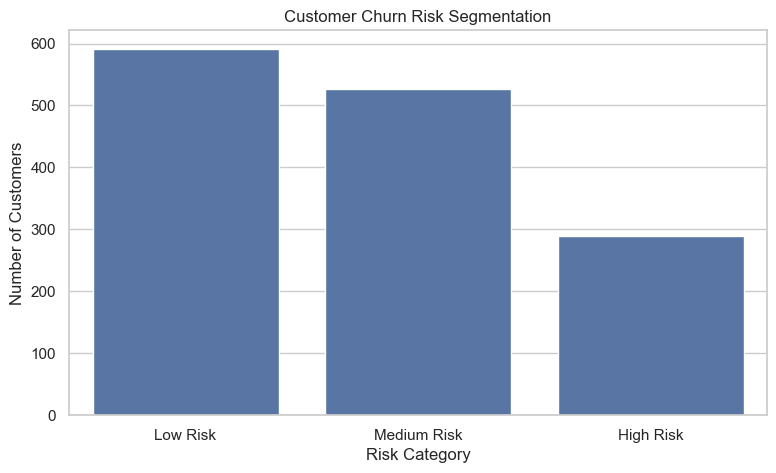

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 5))

sns.countplot(
    data=customer_risk,
    x='Risk Segment',
    order=['Low Risk', 'Medium Risk', 'High Risk']
)

plt.title('Customer Churn Risk Segmentation')
plt.xlabel('Risk Category')
plt.ylabel('Number of Customers')

plt.show()

In [ ]:
import os

os.makedirs('reports', exist_ok=True)

customer_risk.to_csv(
    'reports/customer_risk_segments.csv',
    index=False
)

In [ ]:
customer_risk = df_clean.loc[
    X_test.index,
    [
        'CustomerID',
        'Tenure Months',
        'Contract',
        'Monthly Charges',
        'Internet Service',
        'Tech Support',
        'Online Security',
        'Payment Method',
        'Add-on Services Count'
    ]
].copy()

customer_risk = customer_risk.reset_index(drop=True)

customer_risk['Churn Score'] = rf_test_prob

customer_risk['Predicted Churn'] = rf_test_pred

In [ ]:
conditions = [
    customer_risk['Churn Score'] < rf_best_threshold,
    customer_risk['Churn Score'] < 0.50
]

choices = [
    'Low Risk',
    'Medium Risk'
]

customer_risk['Risk Segment'] = np.select(
    conditions,
    choices,
    default='High Risk'
)

customer_risk['Risk Segment'].value_counts()

Risk Segment
Low Risk       592
Medium Risk    527
High Risk      290
Name: count, dtype: int64

In [ ]:
high_charge_cutoff = X_train['Monthly Charges'].quantile(0.75)


def recommend_retention(row):

    actions = []

    # Risk-based action
    if row['Risk Segment'] == 'High Risk':

        actions.append(
            'Priority retention outreach and satisfaction check'
        )

    elif row['Risk Segment'] == 'Medium Risk':

        actions.append(
            'Proactive customer check-in'
        )

    else:

        actions.append(
            'Regular engagement and loyalty benefits'
        )

    # Contract-based recommendation
    if row['Contract'] == 'Month-to-month':

        actions.append(
            'Offer an annual contract incentive'
        )

    # New customer recommendation
    if row['Tenure Months'] <= 12:

        actions.append(
            'Provide onboarding and personalized support'
        )

    # Technical support recommendation
    if (
        row['Internet Service'] != 'No'
        and row['Tech Support'] == 'No'
    ):

        actions.append(
            'Offer a technical support trial'
        )

    # Monthly charges recommendation
    if row['Monthly Charges'] >= high_charge_cutoff:

        actions.append(
            'Review current plan and offer suitable savings'
        )

    # Payment method recommendation
    if row['Payment Method'] == 'Electronic check':

        actions.append(
            'Offer convenient automatic payment options'
        )

    # Online security recommendation
    if (
        row['Internet Service'] != 'No'
        and row['Online Security'] == 'No'
    ):

        actions.append(
            'Offer an optional online security package'
        )

    return ' | '.join(actions[:3])

In [ ]:
customer_risk['Retention Recommendation'] = (
    customer_risk.apply(
        recommend_retention,
        axis=1
    )
)

In [ ]:
customer_risk[
    [
        'CustomerID',
        'Churn Score',
        'Risk Segment',
        'Retention Recommendation'
    ]
].head(15)

,CustomerID,Churn Score,Risk Segment,Retention Recommendation
0,4376-KFVRS,0.040012,Low Risk,Regular engagement and loyalty benefits | Revi...
1,2754-SDJRD,0.704732,High Risk,Priority retention outreach and satisfaction c...
2,9917-KWRBE,0.076510,Low Risk,Regular engagement and loyalty benefits | Offe...
3,0365-GXEZS,0.425988,Medium Risk,Proactive customer check-in | Offer an annual ...
4,9385-NXKDA,0.035416,Low Risk,Regular engagement and loyalty benefits | Offe...
5,4686-UXDML,0.542066,High Risk,Priority retention outreach and satisfaction c...
6,2227-JRSJX,0.388335,Medium Risk,Proactive customer check-in | Offer an annual ...
7,4830-FAXFM,0.121880,Low Risk,Regular engagement and loyalty benefits | Offe...
8,1830-IPXVJ,0.003343,Low Risk,Regular engagement and loyalty benefits
9,4690-LLKUA,0.382735,Medium Risk,Proactive customer check-in | Offer an annual ...


In [ ]:
high_risk_customers = customer_risk[
    customer_risk['Risk Segment'] == 'High Risk'
].sort_values(
    by='Churn Score',
    ascending=False
)

high_risk_customers.head(20)

,CustomerID,Tenure Months,Contract,Monthly Charges,Internet Service,Tech Support,Online Security,Payment Method,Add-on Services Count,Churn Score,Predicted Churn,Risk Segment,Retention Recommendation
1090,5178-LMXOP,1,Month-to-month,95.10,Fiber optic,No,No,Electronic check,3,0.864174,1,High Risk,Priority retention outreach and satisfaction c...
1221,0295-PPHDO,1,Month-to-month,95.45,Fiber optic,No,No,Electronic check,3,0.862728,1,High Risk,Priority retention outreach and satisfaction c...
1109,1069-XAIEM,1,Month-to-month,85.05,Fiber optic,No,No,Electronic check,2,0.854997,1,High Risk,Priority retention outreach and satisfaction c...
618,9248-OJYKK,1,Month-to-month,76.45,Fiber optic,No,No,Electronic check,1,0.836045,1,High Risk,Priority retention outreach and satisfaction c...
710,6857-VWJDT,1,Month-to-month,95.65,Fiber optic,No,No,Mailed check,3,0.826522,1,High Risk,Priority retention outreach and satisfaction c...
1259,2609-IAICY,1,Month-to-month,77.15,Fiber optic,No,No,Electronic check,1,0.823586,1,High Risk,Priority retention outreach and satisfaction c...
1289,8375-DKEBR,1,Month-to-month,69.60,Fiber optic,No,No,Electronic check,0,0.821810,1,High Risk,Priority retention outreach and satisfaction c...
234,7180-PISOG,1,Month-to-month,74.50,Fiber optic,No,No,Electronic check,1,0.816991,1,High Risk,Priority retention outreach and satisfaction c...
341,1820-TQVEV,1,Month-to-month,69.55,Fiber optic,No,No,Electronic check,0,0.816385,1,High Risk,Priority retention outreach and satisfaction c...
171,2514-GINMM,1,Month-to-month,79.50,Fiber optic,No,No,Electronic check,1,0.816278,1,High Risk,Priority retention outreach and satisfaction c...


In [ ]:
retention_summary = customer_risk.groupby(
    'Risk Segment'
).agg(
    Total_Customers=('CustomerID', 'count'),

    Average_Churn_Score=('Churn Score', 'mean')
).round(3)

print(retention_summary)

              Total_Customers  Average_Churn_Score
Risk Segment                                      
High Risk                 290                0.643
Low Risk                  592                0.051
Medium Risk               527                0.305


In [ ]:
import os

os.makedirs('reports', exist_ok=True)

customer_risk.to_csv(
    'reports/retention_recommendations.csv',
    index=False
)

print("Retention report generated successfully!")

Retention report generated successfully!


In [ ]:
import os
import joblib

os.makedirs("models", exist_ok=True)

# Calculate the training-set charge cutoff
high_charge_cutoff = X_train['Monthly Charges'].quantile(0.75)

# Save model, threshold and recommendation configuration
model_bundle = {
    'model': final_rf_model,
    'threshold': float(rf_best_threshold),
    'high_charge_cutoff': float(high_charge_cutoff)
}

joblib.dump(
    model_bundle,
    'models/churn_rf_bundle.joblib'
)

print("Random Forest model saved successfully!")

Random Forest model saved successfully!
